In [15]:
import pybamm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from battery_utils import step_table, charge_summary

In [16]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%
initial_soc = 0
Q_nom = parameter_values["Nominal cell capacity [A.h]"]
V_nom = 3.6

In [17]:
MCCCV_Charging = pybamm.Experiment([
    "Charge at 2C until 4.0 V",     # Stage 1: fast charge while the anode is empty
    "Charge at 1C until 4.1 V",     # Stage 2: reduced current
    "Charge at 0.5C until 4.2 V",   # Stage 3: slow charge when the cell is nearly full
    "Hold at 4.2 V until C/20",     # CV phase: hold voltage until current drops to C/20
])

In [18]:
sim = pybamm.Simulation(pybamm.lithium_ion.DFN(), experiment=MCCCV_Charging,
                        parameter_values=parameter_values, solver=pybamm.IDAKLUSolver(rtol=1e-6, atol=1e-8))
sol = sim.solve()

In [19]:
t = sol["Time [min]"].entries
t_firstcycle = sol.cycles[0]["Time [min]"].entries[-1]
t_secondcycle = sol.cycles[1]["Time [min]"].entries[-1]
t_thirdcycle = sol.cycles[2]["Time [min]"].entries[-1]
t_end = sol.cycles[3]["Time [min]"].entries[-1]
soc = (initial_soc - sol["Discharge capacity [A.h]"].entries / Q_nom) * 100
u = sol["Negative electrode surface potential difference at separator interface [V]"].entries * 1000  # V -> mV

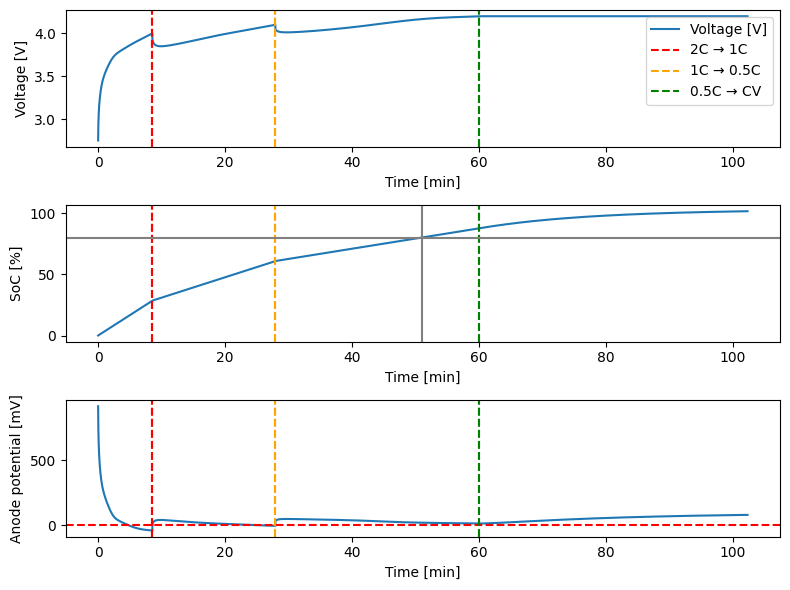

SoC at 10 min: 30.9 %
80% SoC in : 51.0 min


In [20]:
#Anode Potential vs Time
labels = ["2C → 1C", "1C → 0.5C", "0.5C → CV"]
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
ax[0].plot(t, sol["Voltage [V]"].entries, label="Voltage [V]")
ax[1].plot(t, soc, label="SoC [%]")
ax[2].plot(t, u, label="Anode potential [mV]")
ax[0].set_ylabel("Voltage [V]");  ax[0].legend()
ax[1].set_ylabel("SoC [%]"); ax[1].set_xlabel("Time [min]")
ax[2].set_ylabel("Anode potential [mV]"); ax[2].set_xlabel("Time [min]")
ax[2].axhline(0, color="red", linestyle="--")   # horizontal line at 0 mV (plating threshold)
for i in range(3):
    ax[i].axvline(t_firstcycle, color="red", linestyle="--")   # vertical line at the end of first cycle
    ax[i].axvline(t_secondcycle, color="orange", linestyle="--")   # vertical line at the end of second cycle
    ax[i].axvline(t_thirdcycle, color="green", linestyle="--")   # vertical line at the end of third cycle
    ax[i].axvline(t_firstcycle, color="red", linestyle="--", label=labels[0])
    ax[i].axvline(t_secondcycle, color="orange", linestyle="--", label=labels[1])
    ax[i].axvline(t_thirdcycle, color="green", linestyle="--", label=labels[2])
    ax[i].set_xlabel("Time [min]")
    ax[i].tick_params(labelbottom=True)   # show minute values on every subplot
    

# SoC at minute 10
soc_10min = np.interp(10, t, soc)

# Time when SoC reaches 80 %
t_soc80 = np.interp(80, soc, t)

ax[1].axhline(80, color="Grey", linestyle="solid")   # horizontal line at 0 mV (plating threshold)
ax[1].axvline(t_soc80, color="Grey", linestyle="solid")
ax[0].legend(loc="upper right")
plt.tight_layout()
plt.show()
print(f"SoC at 10 min: {soc_10min:.1f} %")
print(f"80% SoC in : {t_soc80:.1f} min")

In [21]:
charge_summary(sol,Q_nom,0,10)

{'SoC at 10 min [%]': 30.9,
 'Time to 80% SoC [min]': 50.99,
 'Total time [min]': 102.36,
 'Final SoC [%]': 101.46,
 'Min anode potential [mV]': -40.58,
 'Time below 0 mV [min]': 6.09}